# Data Preprocessing

Preparring the dataset, so that it is able to be trained for pretranined Convolutional Neural Networks called ResNet18.

## 1. Data Preperation



### 1.1 Load train_labels.csv and match image paths

In [ ]:
# Load train_labels.csv and match image paths
from pathlib import Path
import pandas as pd

DATA_DIR = Path(".")
TRAIN_DIR = DATA_DIR / "train" / "train"

train_df = pd.read_csv(
    DATA_DIR / "train_labels.csv",
    dtype={"image_id": str}
)

train_map = {
    int(p.stem): p
    for p in TRAIN_DIR.iterdir()
    if p.is_file() and p.stem.isdecimal()
}

train_df["path"] = train_df["image_id"].astype(int).map(train_map)

if train_df["path"].isna().any():
    raise FileNotFoundError(
        "Some training image IDs have no matching file."
    )

print("Original training images:", len(train_df))

Original training images: 63660


### 1.2 Identify exact duplicate training images

In [6]:
import hashlib

def calculate_hash(path):
    sha256 = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

train_df["sha256"] = train_df["path"].apply(calculate_hash)

duplicate_rows = train_df[
    train_df.duplicated("sha256", keep=False)
].sort_values("sha256")

print("Training duplicate groups:", duplicate_rows["sha256"].nunique())
print("Files in duplicate groups:", len(duplicate_rows))
print("Extra duplicate copies:", train_df.duplicated("sha256").sum())

Training duplicate groups: 15
Files in duplicate groups: 30
Extra duplicate copies: 15


### 1.3 Check Duplicate Labels

In [7]:
label_counts = train_df.groupby("sha256")["class"].nunique()

conflicting_hashes = label_counts[label_counts > 1].index

conflicting_images = train_df[
    train_df["sha256"].isin(conflicting_hashes)
]

print("Duplicate groups with conflicting labels:", len(conflicting_hashes))

display(conflicting_images[["image_id", "class", "path", "sha256"]])

Duplicate groups with conflicting labels: 0


,image_id,class,path,sha256


### 1.4 Remove Duplicates

In [8]:
if len(conflicting_hashes) > 0:
    raise ValueError(
        "Conflicting duplicate labels found. Review before deduplication."
    )

train_clean_df = (
    train_df.drop_duplicates(subset="sha256", keep="first")
    .copy()
    .reset_index(drop=True)
)

print("Before:", len(train_df))
print("After:", len(train_clean_df))
print("Removed:", len(train_df) - len(train_clean_df))

Before: 63660
After: 63645
Removed: 15


## 2. Trainning-Validation Split 80/20

In [9]:

from sklearn.model_selection import train_test_split

# Using seed 42
SEED = 42

train_split_df, val_split_df = train_test_split(
    train_clean_df,
    test_size=0.20,
    stratify=train_clean_df["class"],
    random_state=SEED
)

train_split_df = train_split_df.reset_index(drop=True)
val_split_df = val_split_df.reset_index(drop=True)

print("Training images:", len(train_split_df))
print("Validation images:", len(val_split_df))
print("Total:", len(train_split_df) + len(val_split_df))


Training images: 50916
Validation images: 12729
Total: 63645


In [ ]:
# Verify that the splits are correct and there are no overlaps
assert len(train_split_df) + len(val_split_df) == len(train_clean_df)

assert set(train_split_df["image_id"]).isdisjoint(
    set(val_split_df["image_id"])
)

assert set(train_split_df["sha256"]).isdisjoint(
    set(val_split_df["sha256"])
)

distribution = pd.DataFrame({
    "Original (%)": train_clean_df["class"].value_counts(normalize=True) * 100,
    "Training (%)": train_split_df["class"].value_counts(normalize=True) * 100,
    "Validation (%)": val_split_df["class"].value_counts(normalize=True) * 100
}).sort_index().round(2)

display(distribution)

print("No overlapping image IDs or exact duplicate hashes.")


,Original (%),Training (%),Validation (%)
class,,,
CatEye,21.80,21.80,21.80
CatFace,10.91,10.91,10.91
CatMouth,10.91,10.91,10.90
CatNose,10.91,10.91,10.90
DogEye,18.19,18.19,18.19
DogFace,9.09,9.09,9.10
DogMouth,9.10,9.10,9.10
DogNose,9.10,9.10,9.10


No overlapping image IDs or exact duplicate hashes.


## 3. Resizing

In [12]:

from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
from torchvision.transforms import functional as TF, InterpolationMode

IMAGE_SIZE = 224

class ResizeAndPad:
    def __init__(self, size=224, fill=0):
        self.size = size
        self.fill = fill

    def __call__(self, image):
        image = image.convert("RGB")
        width, height = image.size

        # Resize proportionally
        scale = self.size / max(width, height)

        new_width = max(1, min(self.size, round(width * scale)))
        new_height = max(1, min(self.size, round(height * scale)))

        image = TF.resize(
            image,
            [new_height, new_width],
            interpolation=InterpolationMode.BILINEAR,
            antialias=True
        )

        # Calculate padding
        dw = self.size - new_width
        dh = self.size - new_height

        # Apply padding evenly
        image = TF.pad(
            image,
            [
                dw // 2,
                dh // 2,
                dw - dw // 2,
                dh - dh // 2
            ],
            fill=self.fill,
            padding_mode="constant"
        )

        return image

resize_transform = transforms.Compose([
    ResizeAndPad(size=IMAGE_SIZE, fill=0)
])


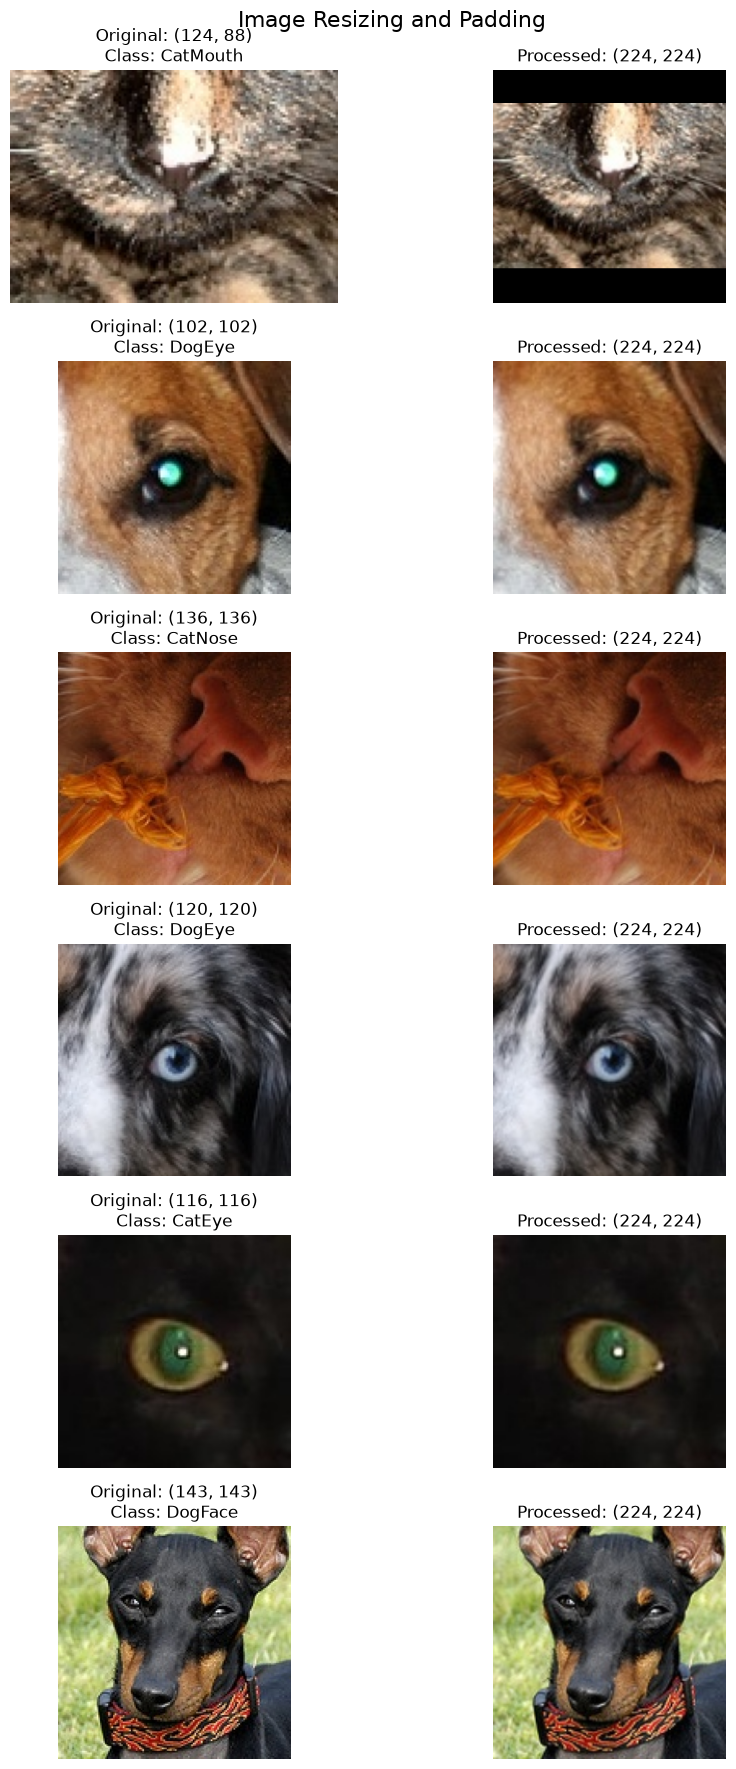

In [13]:

# Select six images from the training subset
samples = train_split_df.sample(n=6, random_state=42)

fig, axes = plt.subplots(6, 2, figsize=(10, 18))

for i, (_, row) in enumerate(samples.iterrows()):
    with Image.open(row["path"]) as img:
        original = img.convert("RGB")
        original_size = original.size

        processed = resize_transform(original)

    # Verify dimensions and channels
    assert processed.size == (224, 224)
    assert processed.mode == "RGB"

    # Original image
    axes[i, 0].imshow(original)
    axes[i, 0].set_title(
        f"Original: {original_size}\n"
        f"Class: {row['class']}"
    )
    axes[i, 0].axis("off")

    # Processed image
    axes[i, 1].imshow(processed)
    axes[i, 1].set_title(
        f"Processed: {processed.size}"
    )
    axes[i, 1].axis("off")

plt.suptitle("Image Resizing and Padding", fontsize=16)
plt.tight_layout()
plt.show()


In [14]:

test_sizes = [
    (28, 28),
    (100, 80),
    (800, 600),
    (500, 1000),
    (224, 224)
]

for width, height in test_sizes:
    image = Image.new("RGB", (width, height), color="white")

    processed = resize_transform(image)

    assert processed.size == (224, 224)
    assert processed.mode == "RGB"

    print(f"{width}x{height} -> {processed.size}")

print("All resizing tests passed!")


28x28 -> (224, 224)
100x80 -> (224, 224)
800x600 -> (224, 224)
500x1000 -> (224, 224)
224x224 -> (224, 224)
All resizing tests passed!


## 4. Normalisation Pixel

In [15]:
import torch
from PIL import Image
from torchvision import transforms

# ImageNet statistics for pretrained ResNet18
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Combine resizing, rescaling, and normalisation
normalise_transform = transforms.Compose([
    ResizeAndPad(size=224, fill=0),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


In [16]:

# Select one training image
sample = train_split_df.iloc[0]

with Image.open(sample["path"]) as image:
    # Apply resizing only
    resized = resize_transform(image)

# Rescale values to 0-1
rescaled = transforms.ToTensor()(resized)

# Apply ImageNet normalisation
normalised = transforms.Normalize(
    mean=IMAGENET_MEAN,
    std=IMAGENET_STD
)(rescaled)

print("Image class:", sample["class"])
print("Original image size:", resized.size)

print("\nAfter rescaling:")
print("Tensor shape:", rescaled.shape)
print("Minimum value:", rescaled.min().item())
print("Maximum value:", rescaled.max().item())

print("\nAfter normalisation:")
print("Tensor shape:", normalised.shape)
print("Minimum value:", normalised.min().item())
print("Maximum value:", normalised.max().item())

# Verify the combined transformation produces the same result
with Image.open(sample["path"]) as image:
    combined_result = normalise_transform(image)

assert torch.allclose(normalised, combined_result)
assert normalised.shape == (3, 224, 224)
assert torch.isfinite(normalised).all()

print("\nPixel normalisation verification passed!")


Image class: CatNose
Original image size: (224, 224)

After rescaling:
Tensor shape: torch.Size([3, 224, 224])
Minimum value: 0.0
Maximum value: 1.0

After normalisation:
Tensor shape: torch.Size([3, 224, 224])
Minimum value: -2.1179039478302
Maximum value: 2.5354249477386475

Pixel normalisation verification passed!


## 5. Label Encoding

In [17]:

# Create a consistent class-to-integer mapping
CLASSES = sorted(train_clean_df["class"].unique())

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(CLASSES)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

# Encode the training and validation labels
train_split_df["label"] = train_split_df["class"].map(class_to_idx)
val_split_df["label"] = val_split_df["class"].map(class_to_idx)

# Verify the encoding
assert len(CLASSES) == 8
assert train_split_df["label"].notna().all()
assert val_split_df["label"].notna().all()

print("Class mapping:", class_to_idx)

print("\nTraining examples:")
print(train_split_df[["image_id", "class", "label"]].head())


Class mapping: {'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}

Training examples:
  image_id     class  label
0    26977   CatNose      3
1    43790  DogMouth      6
2    60045    CatEye      0
3    47430    DogEye      4
4    50148  DogMouth      6


## 6. Data Augmentation

Introduce Flipping, rotaions and changing Brightness

In [19]:
from torchvision import transforms

# Augmentation applied only to training images
train_augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15, fill=0),
    transforms.ColorJitter(brightness=0.2)
])

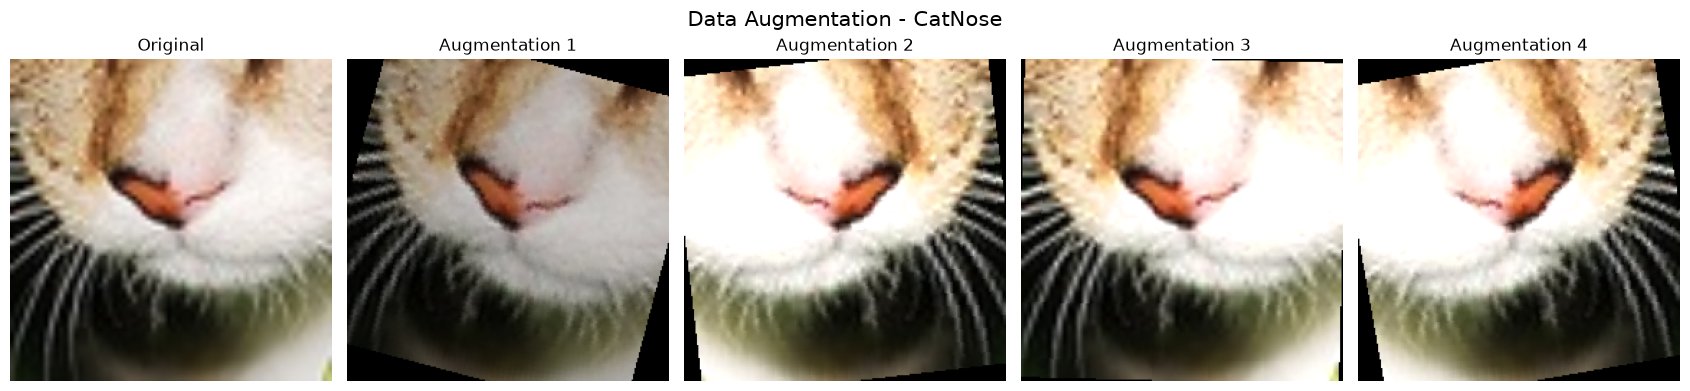

In [20]:
from PIL import Image
import matplotlib.pyplot as plt

# Select one image from the training subset
sample = train_split_df.iloc[0]

with Image.open(sample["path"]) as img:
    original = resize_transform(img)

# Generate four augmented versions
images = [original] + [
    train_augmentation(original) for _ in range(4)
]

titles = [
    "Original",
    "Augmentation 1",
    "Augmentation 2",
    "Augmentation 3",
    "Augmentation 4"
]

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"Data Augmentation - {sample['class']}",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 7. Data Loaders

In [ ]:
# Combine the preprocessing transformations
from torchvision import transforms

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training: resizing + augmentation + normalisation
train_transform = transforms.Compose([
    ResizeAndPad(size=224, fill=0),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15, fill=0),
    transforms.ColorJitter(brightness=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# Validation and test: no random augmentation
eval_transform = transforms.Compose([
    ResizeAndPad(size=224, fill=0),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


In [ ]:
# Create PyTorch Dataset class for facial feature images
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class FacialFeatureDataset(Dataset):
    def __init__(self, dataframe, transform=None, labelled=True):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.labelled = labelled

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["path"]) as image:
            image = image.convert("RGB")

            if self.transform is not None:
                image = self.transform(image)

        if self.labelled:
            label = int(row["label"])
            return image, label

        # Test images have no labels
        return image, str(row["image_id"])


In [ ]:

BATCH_SIZE = 32

train_dataset = FacialFeatureDataset(
    train_split_df,
    transform=train_transform
)

val_dataset = FacialFeatureDataset(
    val_split_df,
    transform=eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


In [ ]:

# Get the first training batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

assert images.shape[1:] == (3, 224, 224)
assert labels.dtype == torch.int64
assert torch.isfinite(images).all()
assert labels.min() >= 0
assert labels.max() < 8

print("DataLoader verification passed!")
